# 08 · Rejection-sampling fine-tuning (RFT) for M1 and M2

Answer-only LoRA teaches the decoder-only models to skip their reasoning (notebooks 06–07). **RFT**, a simple
reinforcement-style recipe (expert iteration with a binary reward), trains on the model's *own* best attempts, reasoning included:

1. **Sample.** The base model answers every training window 4 times, using the zero-shot sampling settings.
2. **Score.** Each finished, strictly valid sample gets the exact F1 of its starts inside the window's owned block, against gold.
3. **Select.** Keep the best sample if F1 ≥ 0.5; otherwise drop the window. Gold only *chooses* a sample; it never enters the text.
4. **Train.** One-pass LoRA on prompt → own thought → own JSON → turn end.

**v1** used 300 training windows. **v2** keeps every setting and covers all 1,306 windows of the same 1,000 videos used by the direct LoRA. RFT is a dev-only follow-up after the freeze; it was never run on test.

In [1]:
%matplotlib inline
import json, statistics
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from nbcommon import *

pd.set_option("display.max_colwidth", 80)
RUN_GPU = False   # True only on the training/inference machine (needs the models and a GPU)
print("project:", ROOT.name, "| run outputs read from:", A.relative_to(ROOT))

project: FinalProject | run outputs read from: artifacts


## 1. Training-window manifests (gold-free)

In [2]:
run(["python", "scripts/rft_build.py", "manifest", "--train-windows", rel(TRAIN_WINDOWS), "--max-windows", "300",
     "--output", "artifacts/rft-v1/train_manifest.jsonl"], RUN_GPU)
run(["python", "scripts/rft_build.py", "manifest", "--train-windows", rel(TRAIN_WINDOWS), "--max-windows", "100000",
     "--exclude", "artifacts/rft-v1/train_manifest.jsonl", "--output", "artifacts/rft-v2/train_manifest.jsonl"], RUN_GPU)
for name, path in [("v1", RFT1 / "train_manifest.jsonl"), ("v2 new windows", RFT2 / "train_manifest.jsonl"), ("v1+v2", RFT2 / "union_manifest.jsonl")]:
    rows = load_jsonl(path)
    print(f"{name}: {len(rows)} windows from {len({r['window']['video_id'] for r in rows})} videos")

[not run here; RUN_GPU=False]  $ python scripts/rft_build.py manifest --train-windows artifacts/windows/dev-v2/train_windows.jsonl --max-windows 300 --output artifacts/rft-v1/train_manifest.jsonl
[not run here; RUN_GPU=False]  $ python scripts/rft_build.py manifest --train-windows artifacts/windows/dev-v2/train_windows.jsonl --max-windows 100000 --exclude artifacts/rft-v1/train_manifest.jsonl --output artifacts/rft-v2/train_manifest.jsonl
v1: 300 windows from 233 videos
v2 new windows: 1006 windows from 767 videos
v1+v2: 1306 windows from 1000 videos


## 2. Sampling

* **v1:** sampled through the existing vLLM services (OpenAI-compatible endpoints; the API key is read from stdin and never stored).
* **v2:** sampled with the local vLLM driver, using identical sampling settings and the same per-window seed scheme.

In [3]:
for alias in ["M1", "M2"]:
    run(["python", "scripts/infer_endpoint_zs.py", "--alias", alias, "--windows", "artifacts/rft-v1/train_manifest.jsonl",
         "--output", f"artifacts/rft-v1/samples/{alias}-seed1001", "--base-url", "$ENDPOINT_URL", "--concurrency", "16",
         "--seed", "1001"], RUN_GPU, env="API key read from stdin")
    run(["$VLLM_PYTHON", "scripts/infer_vllm_pair.py", "--alias", alias, "--arms", "ZS",
         "--windows", "artifacts/rft-v2/train_manifest.jsonl", "--output", f"artifacts/rft-v2/samples/{alias}-seed1001",
         "--seed", "1001", "--max-num-seqs", "256", "--batch-size", "1006", "--max-new-tokens", "32768"], RUN_GPU)
print("(repeated for seeds 2002, 3003, 4004)")
rows = []
for version, base, sub in [("v1", RFT1, ""), ("v2", RFT2, "ZS/")]:
    for alias in ["M1", "M2"]:
        for seed in [1001, 2002, 3003, 4004]:
            s = load_json(base / f"samples/{alias}-seed{seed}/{sub}summary.json")
            seconds = s.get("generation_seconds", s.get("this_invocation_seconds"))
            rows.append({"version": version, "model": alias, "seed": seed, "windows": s["requested_windows"],
                         "ok videos": s["status_counts"].get("ok", 0), "minutes": round(seconds / 60, 1),
                         "output tokens": s["completion_tokens"]})
display(pd.DataFrame(rows).set_index(["version", "model", "seed"]))

[not run here; RUN_GPU=False]  $ python scripts/infer_endpoint_zs.py --alias M1 --windows artifacts/rft-v1/train_manifest.jsonl --output artifacts/rft-v1/samples/M1-seed1001 --base-url $ENDPOINT_URL --concurrency 16 --seed 1001   # API key read from stdin
[not run here; RUN_GPU=False]  $ $VLLM_PYTHON scripts/infer_vllm_pair.py --alias M1 --arms ZS --windows artifacts/rft-v2/train_manifest.jsonl --output artifacts/rft-v2/samples/M1-seed1001 --seed 1001 --max-num-seqs 256 --batch-size 1006 --max-new-tokens 32768
[not run here; RUN_GPU=False]  $ python scripts/infer_endpoint_zs.py --alias M2 --windows artifacts/rft-v1/train_manifest.jsonl --output artifacts/rft-v1/samples/M2-seed1001 --base-url $ENDPOINT_URL --concurrency 16 --seed 1001   # API key read from stdin
[not run here; RUN_GPU=False]  $ $VLLM_PYTHON scripts/infer_vllm_pair.py --alias M2 --arms ZS --windows artifacts/rft-v2/train_manifest.jsonl --output artifacts/rft-v2/samples/M2-seed1001 --seed 1001 --max-num-seqs 256 --batch-s

windows  ok videos  minutes  output tokens
version model seed                                            
v1      M1    1001      300        232     48.7        2232579
              2002      300        233     49.1        2253977
              3003      300        233     48.8        2261339
              4004      300        233     49.4        2312221
        M2    1001      300        233     48.8        1594232
              2002      300        233     48.1        1554757
              3003      300        233     48.5        1514802
              4004      300        233     49.3        1560100
v2      M1    1001     1006        766     13.6        7739864
              2002     1006        765     13.4        7816137
              3003     1006        763     12.9        7826091
              4004     1006        764     13.2        7793744
        M2    1001     1006        766     15.0        5599673
              2002     1006        767     14.1        5380130
              3003     1006        766     13.5        5398252
              4004     1006        766     14.0        5422568

## 3. Selection (best of N, owned-start F1 ≥ 0.5)

In [4]:
run(["python", "scripts/rft_build.py", "select", "--train-windows", rel(TRAIN_WINDOWS),
     "--manifest", "artifacts/rft-v2/union_manifest.jsonl", "--samples", "<8 sample windows.jsonl files>",
     "--min-f1", "0.5", "--output", "artifacts/windows/dev-v2/rft_M1_v2.jsonl"], RUN_GPU)
rows = []
for version in ["v1", "v2"]:
    for alias in ["M1", "M2"]:
        s = load_json(DEV_PACK / f"rft_{alias}_{version}.summary.json")
        rows.append({"version": version, "model": alias, "windows sampled": s["manifest_windows"], "samples": s["samples_read"],
                     "kept windows": s["kept_windows"], "mean F1 of valid samples": round(s["mean_valid_sample_f1"], 3),
                     "mean F1 of kept samples": round(s["mean_kept_f1"], 3), **s["drop_counts"]})
display(pd.DataFrame(rows).fillna(0).set_index(["version", "model"]))

[not run here; RUN_GPU=False]  $ python scripts/rft_build.py select --train-windows artifacts/windows/dev-v2/train_windows.jsonl --manifest artifacts/rft-v2/union_manifest.jsonl --samples '<8 sample windows.jsonl files>' --min-f1 0.5 --output artifacts/windows/dev-v2/rft_M1_v2.jsonl


windows sampled  samples  kept windows  \
version model                                           
v1      M1                 300     1200           146   
        M2                 300     1200           134   
v2      M1                1306     5224           599   
        M2                1306     5224           573   

               mean F1 of valid samples  mean F1 of kept samples  \
version model                                                      
v1      M1                        0.362                    0.699   
        M2                        0.391                    0.720   
v2      M1                        0.350                    0.705   
        M2                        0.383                    0.719   

               window_best_below_min_f1  sample_not_ok  
version model                                           
v1      M1                          154            1.0  
        M2                          166            0.0  
v2      M1                          707           11.0  
        M2                          733            3.0

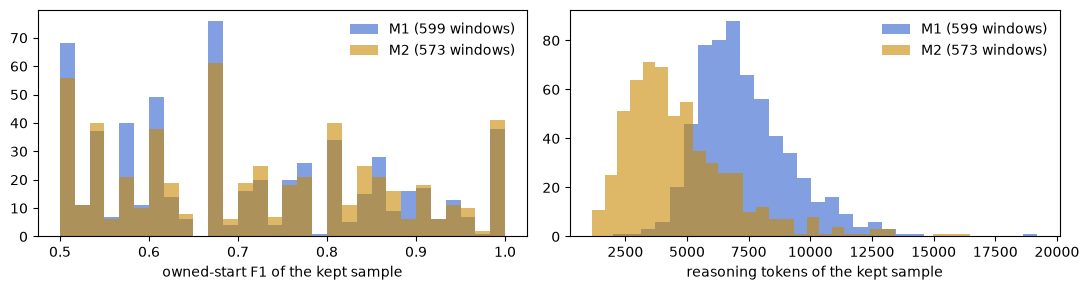

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, key, label in [(axes[0], "window_f1", "owned-start F1 of the kept sample"), (axes[1], "reasoning_tokens", "reasoning tokens of the kept sample")]:
    for alias, color in [("M1", "#2f5fd0"), ("M2", "#c98a00")]:
        kept = load_jsonl(DEV_PACK / f"rft_{alias}_v2.jsonl")
        ax.hist([r["rft_meta"][key] or 0 for r in kept], bins=30, alpha=.6, color=color, label=f"{alias} ({len(kept)} windows)")
    ax.set_xlabel(label); ax.legend(frameon=False)
plt.tight_layout()

## 4. Training (same LoRA settings as direct LoRA; warmup 3; loss on everything after the prompt)

[not run here; RUN_GPU=False]  $ python scripts/train_lora.py --alias M1 --windows artifacts/windows/dev-v2/rft_M1_v2.jsonl --max-steps 0 --target-modules q_proj,k_proj,v_proj,o_proj --learning-rate 2e-4 --lr-schedule cosine --warmup-steps 3 --grad-accum 8 --checkpoint-every 100 --output artifacts/rft-v2/M1-rft-lora
[not run here; RUN_GPU=False]  $ python scripts/train_lora.py --alias M2 --windows artifacts/windows/dev-v2/rft_M2_v2.jsonl --max-steps 0 --target-modules q_proj,k_proj,v_proj,o_proj --learning-rate 2e-4 --lr-schedule cosine --warmup-steps 3 --grad-accum 8 --checkpoint-every 100 --output artifacts/rft-v2/M2-rft-lora


windows  optimizer steps  tokens processed  mean loss  minutes  \
version model                                                                   
v1      M1         146               19           1541665      0.436      2.6   
        M2         134               17           1025015      0.214      7.4   
v2      M1         599               75           6608014      0.421     12.0   
        M2         573               72           4717684      0.215     34.8   

                     final context  
version model                       
v1      M1     rft_self_samples_v1  
        M2     rft_self_samples_v1  
v2      M1     rft_self_samples_v1  
        M2     rft_self_samples_v1

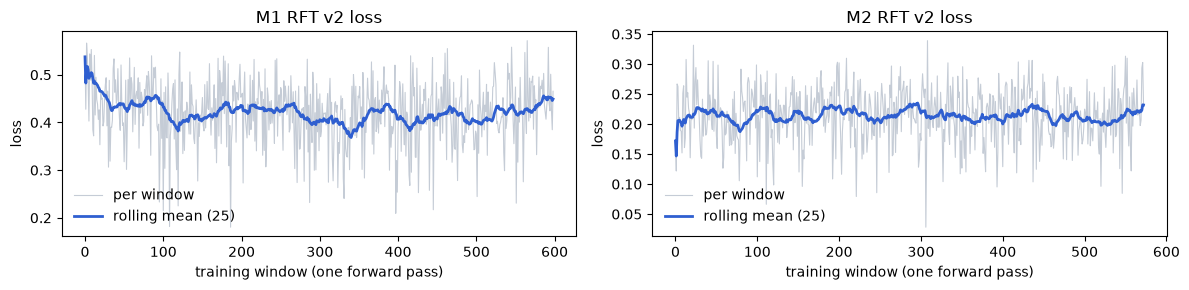

In [6]:
for alias in ["M1", "M2"]:
    run(["python", "scripts/train_lora.py", "--alias", alias, "--windows", f"artifacts/windows/dev-v2/rft_{alias}_v2.jsonl",
         "--max-steps", "0", "--target-modules", "q_proj,k_proj,v_proj,o_proj", "--learning-rate", "2e-4", "--lr-schedule", "cosine",
         "--warmup-steps", "3", "--grad-accum", "8", "--checkpoint-every", "100", "--output", f"artifacts/rft-v2/{alias}-rft-lora"], RUN_GPU)
rows = []
for version, base in [("v1", RFT1), ("v2", RFT2)]:
    for alias in ["M1", "M2"]:
        r = load_json(base / f"{alias}-rft-lora/report.json")
        rows.append({"version": version, "model": alias, "windows": r["actual_steps"], "optimizer steps": r["planned_optimizer_steps"],
                     "tokens processed": r["teacher_forcing_tokens"], "mean loss": round(r["mean_loss"], 3),
                     "minutes": round(r["training_seconds"] / 60, 1), "final context": r["final_context"]})
display(pd.DataFrame(rows).set_index(["version", "model"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, alias in zip(axes, ["M1", "M2"]):
    plot_loss(RFT2 / f"{alias}-rft-lora/steps.jsonl", f"{alias} RFT v2 loss", ax=ax, window=25)
plt.tight_layout()

## 5. Dev evaluation (200 videos; same inference settings as zero-shot)

In [7]:
def think(path):
    return int(statistics.median((r.get("usage") or {}).get("reasoning_tokens") or 0 for r in load_jsonl(path)))

rows = []
for alias in ["M1", "M2"]:
    direct_ft, zs, direct_boot = paired_metrics(paired_file(alias, "dev"))
    v1, _, v1_boot = paired_metrics(RFT1 / f"{alias}-rft-dev-paired.json")
    v2, _, v2_boot = paired_metrics(RFT2 / f"{alias}-rft-dev-paired.json")
    _, _, v2v1 = paired_metrics(RFT2 / f"{alias}-v2-vs-v1-paired.json")
    check = recompute(DEV_RECORDS, RFT2 / f"{alias}-dev/FT/predictions.jsonl")["aggregate"]["macro_exact_f1"]
    assert abs(check - v2["exact_f1"]) < 1e-12
    for label, m, boot, path in [("zero-shot", zs, None, S5 / f"{alias}-dev/ZS/windows.jsonl"),
                                 ("direct LoRA", direct_ft, direct_boot, S5 / f"{alias}-dev/FT/windows.jsonl"),
                                 ("RFT v1", v1, v1_boot, RFT1 / f"{alias}-dev/FT/windows.jsonl"),
                                 ("RFT v2", v2, v2_boot, RFT2 / f"{alias}-dev/FT/windows.jsonl")]:
        rows.append({"model": alias, "config": label, "exact F1": round(m["exact_f1"], 3),
                     "− zero-shot [95% CI]": "" if boot is None else "%+.3f [%+.3f, %+.3f]" % (boot["mean_difference"], *boot["confidence_interval"]),
                     "failed": m["failed"], "pred/ref chapters": round(m["pred_per_ref"], 2), "median thinking": think(path)})
    print(f"{alias}: RFT v2 − RFT v1 = {v2v1['mean_difference']:+.3f} [{v2v1['confidence_interval'][0]:+.3f}, {v2v1['confidence_interval'][1]:+.3f}]")
display(pd.DataFrame(rows).set_index(["model", "config"]))

M1: RFT v2 − RFT v1 = +0.031 [+0.010, +0.052]
M2: RFT v2 − RFT v1 = -0.002 [-0.018, +0.013]


exact F1     − zero-shot [95% CI]  failed  \
model config                                                   
M1    zero-shot       0.420                                1   
      direct LoRA     0.379  -0.042 [-0.072, -0.012]      10   
      RFT v1          0.409  -0.012 [-0.035, +0.012]       0   
      RFT v2          0.440  +0.019 [-0.003, +0.041]       4   
M2    zero-shot       0.459                                0   
      direct LoRA     0.346  -0.114 [-0.144, -0.084]       8   
      RFT v1          0.467  +0.007 [-0.007, +0.021]       0   
      RFT v2          0.464  +0.005 [-0.010, +0.020]       0   

                   pred/ref chapters  median thinking  
model config                                           
M1    zero-shot                 1.17             7191  
      direct LoRA               0.99             3327  
      RFT v1                    1.17             6280  
      RFT v2                    1.09             6071  
M2    zero-shot                 1.46             4903  
      direct LoRA               0.79                0  
      RFT v1                    1.48             4596  
      RFT v2                    1.47             4630

## 6. Takeaway

* **RFT repairs the direct-LoRA damage:** thinking returns, failures drop, and the chapter count returns to zero-shot level.
* **M1 gains with more data.** RFT v2 reaches **0.440** dev exact F1. That is significantly above RFT v1 (+0.031 [+0.010, +0.052]) and trends above zero-shot (+0.019 [−0.003, +0.041]).
* **M2 does not gain.** It stays at zero-shot level, 0.464 vs 0.459.
* **Not tested on the held-out set.** A test run would need a new, declared configuration and freeze.